# Decision Tree Algorithms and Ensemble Methods

This notebook uses the Wine dataset to explore classification techniques based on Decision Trees and Ensemble Learning methods. Implement Decision Tree, Random Forest, AdaBoost, and Stacking classifiers to predict different wine categories and compare their effectiveness on the classification task. Evaluate each model using performance metrics such as accuracy and a confusion matrix to analyze prediction results and identify the most effective approach.


In [1]:
# Import necessary libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
# Load the Wine dataset (assuming the file is 'wine.csv' in your 'Datasets' folder)
wine_data = pd.read_csv('WineData.csv')


## Drop the id
wine_data = wine_data.drop('Id', axis=1)
# Display the first few rows of the dataset
print(wine_data.head())


   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [5]:
wine_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 107.3 KB


### Split the Dataset into Features and Target



In [6]:
# Split the dataset into features (X) and target variable (y)
X = wine_data.drop('quality', axis=1)  # Features
y = wine_data['quality']  # Target variable (wine class)


### Split the Data into Training and Test Sets




In [7]:
# Split the data into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Train the Decision Tree Classifier


In [8]:
# Create and train the Decision Tree model
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)


DecisionTreeClassifier(random_state=42)

### Train the Gradient Boosting Classifier

In [9]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

### Train the Random Forest Classifier


In [10]:
# Train the Random Forest Classifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Make Predictions on the Test Set



In [11]:
# Predict on the test set
y_pred = dt.predict(X_test)
y_pred_gb = gb.predict(X_test)
y_pred_rf = rf.predict(X_test)

### Evaluate the Model's Performance

In [12]:
# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
accuracy_gb = accuracy_score(y_test, y_pred_gb)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f'Accuracy of Gradient Boosting Classifier: {accuracy_gb:.2f}')
print(f'Accuracy of Random Forest Classifier: {accuracy_rf:.2f}')
print(f'Accuracy of Decision Tree: {accuracy:.2f}')


Accuracy of Gradient Boosting Classifier: 0.69
Accuracy of Random Forest Classifier: 0.70
Accuracy of Decision Tree: 0.53


### Confusion Matrix



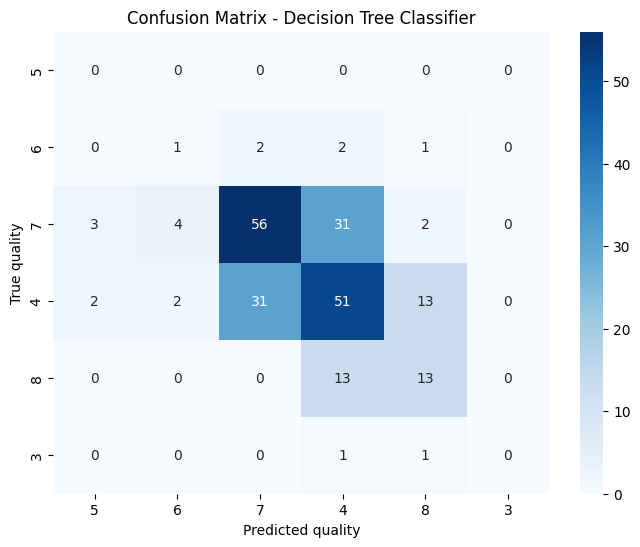

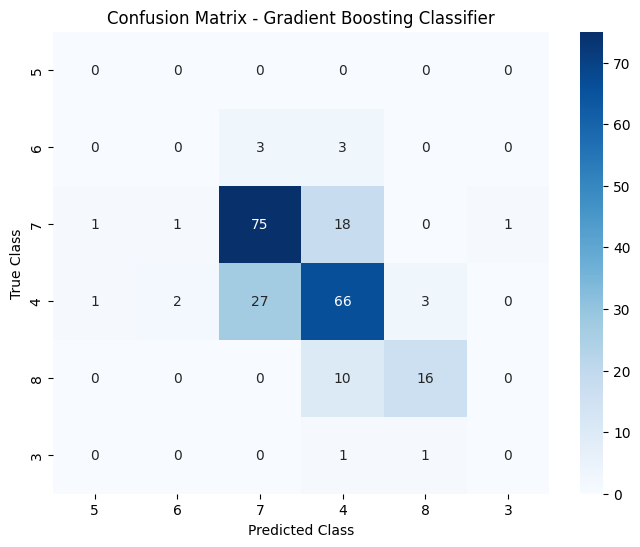

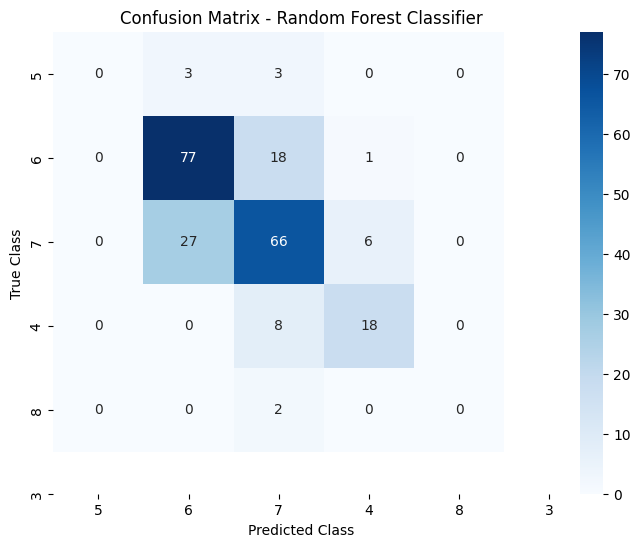

In [13]:
# Confusion Matrix Visualization
conf_matrix = confusion_matrix(y_test, y_pred)

# decision tree confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=y.unique(), yticklabels=y.unique())
plt.title("Confusion Matrix - Decision Tree Classifier")
plt.xlabel("Predicted quality")
plt.ylabel("True quality")
plt.show()

# Confusion Matrix Visualization for Gradient Boosting
conf_matrix_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_gb, annot=True, fmt='d', cmap='Blues', xticklabels=y.unique(), yticklabels=y.unique())
plt.title('Confusion Matrix - Gradient Boosting Classifier')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.show()

# Confusion Matrix Visualization for Random Forest
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf, annot=True, fmt='d', cmap='Blues', xticklabels=y.unique(), yticklabels=y.unique())
plt.title('Confusion Matrix - Random Forest Classifier')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.show()
